## 1. Import libraries

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram

print("Clustering libraries imported.")


Clustering libraries imported.


## 2. Load and audit the dataset

In [2]:
candidate_paths = [
    "../datasets/mall_customers.csv",
    "datasets/mall_customers.csv",
    "mall_customers.csv",
    "/mnt/data/mall_customers.csv",
]
DATA_PATH = next((p for p in candidate_paths if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not locate mall_customers.csv. Put it in ../datasets/ or datasets/, "
        "or update DATA_PATH to the correct path."
    )

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("Data Type"))
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))
print("\nDuplicate rows:", df.duplicated().sum())
display(df.head())


Loaded: ../datasets/mall_customers.csv
Shape: (200, 5)

Data types:


,Data Type
CustomerID,int64
Gender,str
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64



Missing values:


,Missing Values
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0



Duplicate rows: 0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Exploratory data analysis

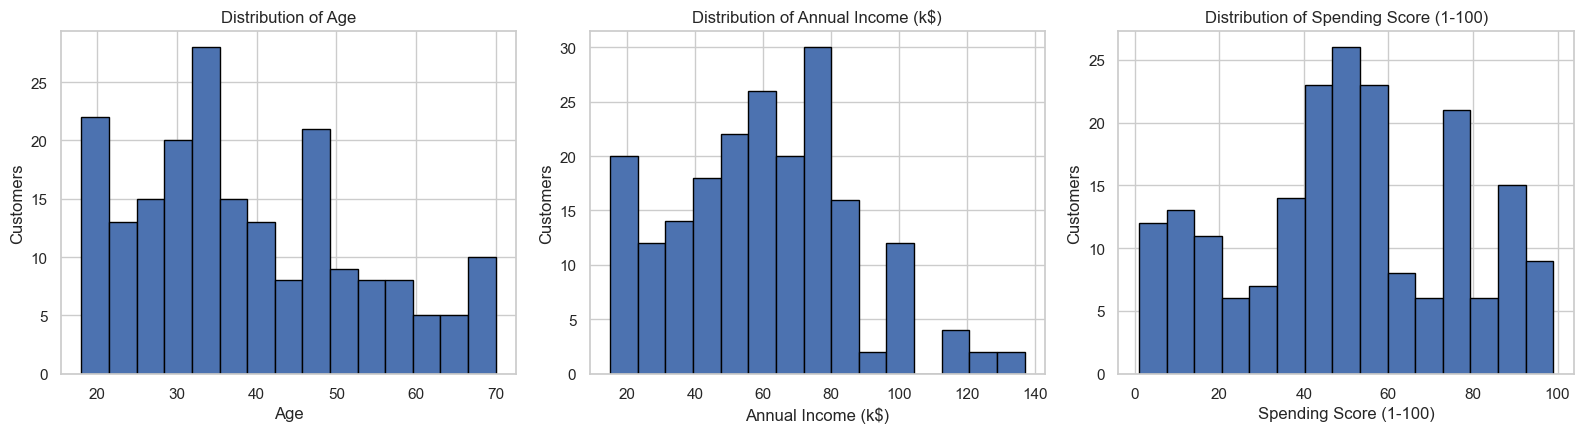

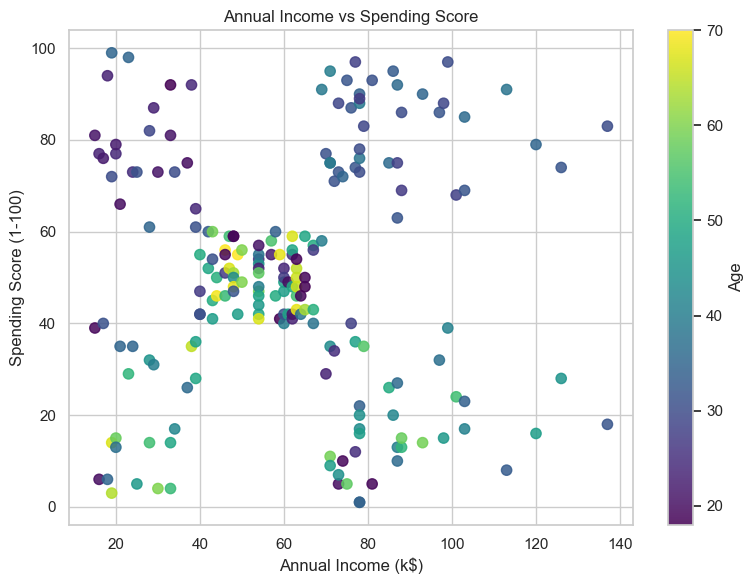

,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


In [3]:
required_columns = ["CustomerID", "Gender", "Age", "Annual Income (k$)", "Spending Score (1-100)"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise KeyError(f"Dataset is missing required columns: {missing_columns}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["Age", "Annual Income (k$)", "Spending Score (1-100)"]):
    ax.hist(df[col].dropna(), bins=15, edgecolor="black")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Customers")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"],
                      c=df["Age"], cmap="viridis", s=55, alpha=0.85)
plt.colorbar(scatter, label="Age")
plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

display(df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].describe().round(2))


## 4. Feature selection and standardisation

`CustomerID` is an identifier, not a meaningful behavioural feature, and `Gender` is excluded to preserve the original notebook's numeric feature scope. Age, annual income, and spending score are standardised because distance-based clustering is sensitive to feature scales.

In [4]:
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].copy()

# Numeric missing values, if any, are imputed with feature medians.
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

processed = df[["CustomerID", "Gender"] + features].copy()
for i, col in enumerate(features):
    processed[col + "_Scaled"] = X_scaled[:, i]

os.makedirs("../datasets", exist_ok=True)
processed.to_csv("../datasets/mall_customers_preprocessed.csv", index=False)

print("Feature matrix:", X.shape)
print("Scaled means:", np.round(X_scaled.mean(axis=0), 4))
print("Scaled standard deviations:", np.round(X_scaled.std(axis=0), 4))


Feature matrix: (200, 3)
Scaled means: [-0. -0. -0.]
Scaled standard deviations: [1. 1. 1.]


## 5. K-Means — choose cluster count with Elbow and Silhouette

,Number of clusters (k),Inertia,Silhouette Score
0,2,389.3862,0.3355
1,3,295.2122,0.3578
2,4,205.2251,0.4040
3,5,168.2476,0.4166
4,6,133.8684,0.4284
5,7,117.0116,0.4172
6,8,103.8733,0.4082
7,9,93.0929,0.4177
8,10,82.3852,0.4066


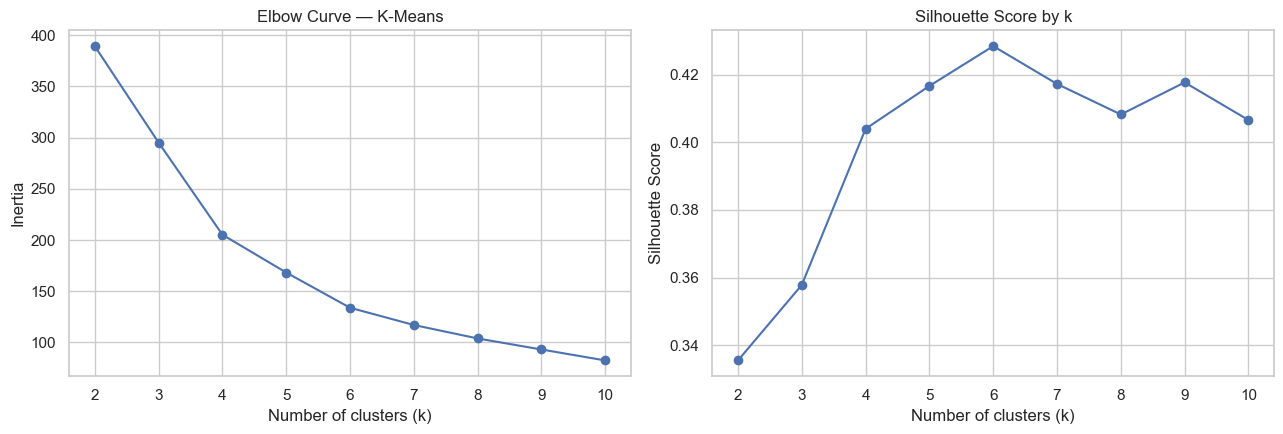

Chosen k for comparison: 6 (retained from the original review notebook; consider the plots when explaining this choice).


In [5]:
k_values = list(range(2, 11))
elbow_rows = []

for k in k_values:
    candidate = KMeans(n_clusters=k, init="k-means++", random_state=RANDOM_STATE, n_init=10)
    candidate_labels = candidate.fit_predict(X_scaled)
    elbow_rows.append({
        "Number of clusters (k)": k,
        "Inertia": candidate.inertia_,
        "Silhouette Score": silhouette_score(X_scaled, candidate_labels)
    })

elbow_table = pd.DataFrame(elbow_rows)
display(elbow_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(elbow_table["Number of clusters (k)"], elbow_table["Inertia"], marker="o")
axes[0].set_title("Elbow Curve — K-Means")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(k_values)

axes[1].plot(elbow_table["Number of clusters (k)"], elbow_table["Silhouette Score"], marker="o")
axes[1].set_title("Silhouette Score by k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(k_values)
plt.tight_layout()
plt.show()

chosen_k = 6
print("Chosen k for comparison:", chosen_k,
      "(retained from the original review notebook; consider the plots when explaining this choice).")


## 6. Evaluation helper for unsupervised clustering

In [6]:
clustering_results = {}

def evaluate_clustering(name, labels, model=None):
    labels = np.asarray(labels)
    unique_clusters = np.unique(labels)
    if len(unique_clusters) < 2 or len(unique_clusters) >= len(labels):
        raise ValueError(f"{name}: internal metrics require between 2 and n-1 clusters.")

    result = {
        "Algorithm": name,
        "Number of clusters": len(unique_clusters),
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X_scaled, labels),
    }

    print(f"\n{'='*70}\n{name}\n{'='*70}")
    display(pd.DataFrame([result]).round(4))
    print("Cluster sizes:")
    display(pd.Series(labels, name="Cluster").value_counts().sort_index().rename("Customers").to_frame())

    clustering_results[name] = {"metrics": result, "labels": labels, "model": model}
    return result


## 7. Model 1 — K-Means

In [7]:
kmeans_model = KMeans(
    n_clusters=chosen_k, init="k-means++", random_state=RANDOM_STATE, n_init=10
)
kmeans_labels = kmeans_model.fit_predict(X_scaled)
kmeans_metrics = evaluate_clustering("K-Means", kmeans_labels, kmeans_model)



K-Means


,Algorithm,Number of clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,6,0.4284,0.8254,135.1021


Cluster sizes:


,Customers
Cluster,
0,45
1,39
2,33
3,39
4,23
5,21


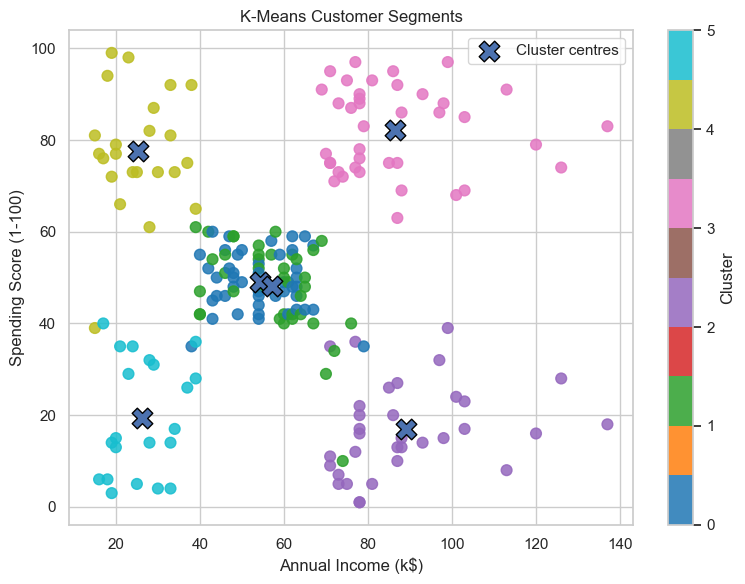

In [8]:
# K-Means cluster visualisation in the original feature space
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"],
                      c=kmeans_labels, cmap="tab10", s=60, alpha=0.85)
plt.scatter(
    scaler.inverse_transform(kmeans_model.cluster_centers_)[:, 1],
    scaler.inverse_transform(kmeans_model.cluster_centers_)[:, 2],
    marker="X", s=220, edgecolor="black", label="Cluster centres"
)
plt.title("K-Means Customer Segments")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()


## 8. Hierarchical clustering — dendrogram

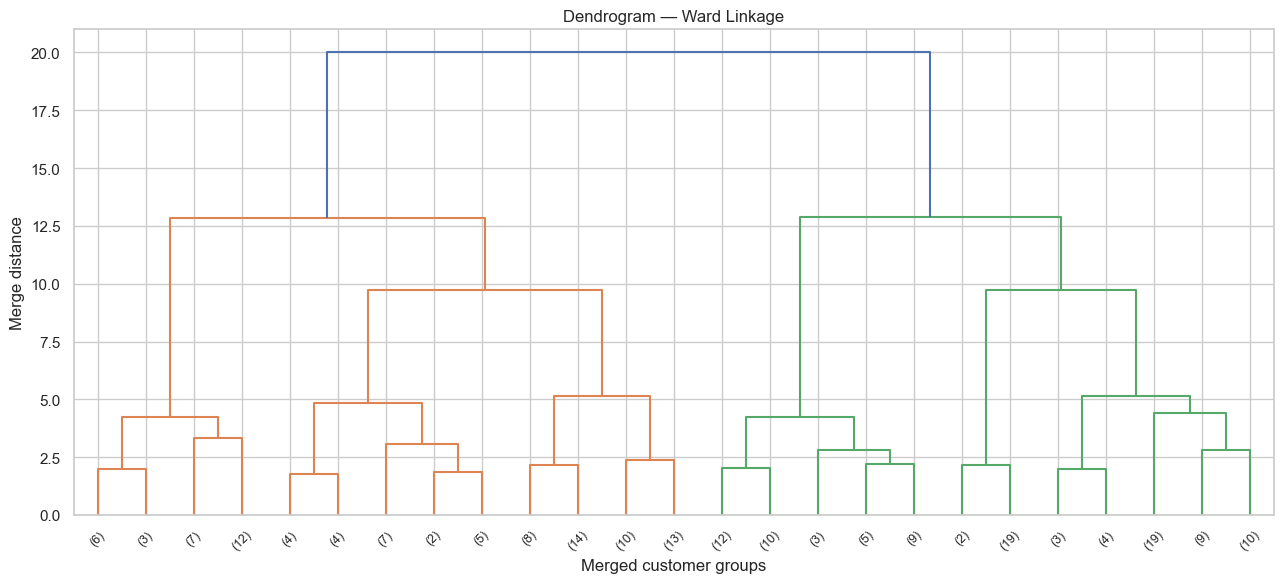

In [9]:
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(13, 6))
dendrogram(Z, truncate_mode="lastp", p=25, leaf_rotation=45, leaf_font_size=9)
plt.title("Dendrogram — Ward Linkage")
plt.xlabel("Merged customer groups")
plt.ylabel("Merge distance")
plt.tight_layout()
plt.show()


## 9. Model — Agglomerative Hierarchical Clustering (Ward linkage)

In [10]:
agg_ward_model = AgglomerativeClustering(n_clusters=chosen_k, linkage="ward")
agg_ward_labels = agg_ward_model.fit_predict(X_scaled)
agg_ward_metrics = evaluate_clustering("Agglomerative (Ward linkage)", agg_ward_labels, agg_ward_model)



Agglomerative (Ward linkage)


,Algorithm,Number of clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Agglomerative (Ward linkage),6,0.4201,0.8521,127.9865


Cluster sizes:


,Customers
Cluster,
0,45
1,45
2,39
3,28
4,22
5,21


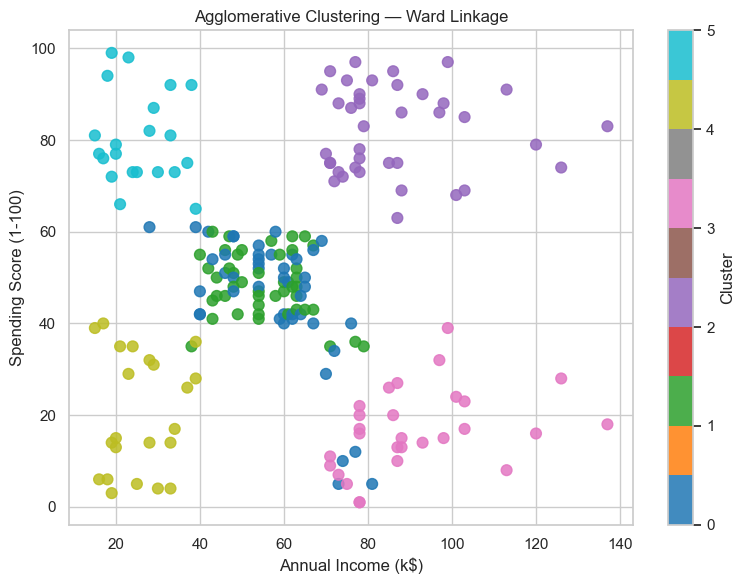

In [11]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"],
                      c=agg_ward_labels, cmap="tab10", s=60, alpha=0.85)
plt.title("Agglomerative Clustering — Ward Linkage")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()


## 9. Model — Agglomerative Hierarchical Clustering (Complete linkage)

In [12]:
agg_complete_model = AgglomerativeClustering(n_clusters=chosen_k, linkage="complete")
agg_complete_labels = agg_complete_model.fit_predict(X_scaled)
agg_complete_metrics = evaluate_clustering("Agglomerative (Complete linkage)", agg_complete_labels, agg_complete_model)



Agglomerative (Complete linkage)


,Algorithm,Number of clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Agglomerative (Complete linkage),6,0.3746,1.0005,109.4154


Cluster sizes:


,Customers
Cluster,
0,35
1,39
2,57
3,16
4,21
5,32


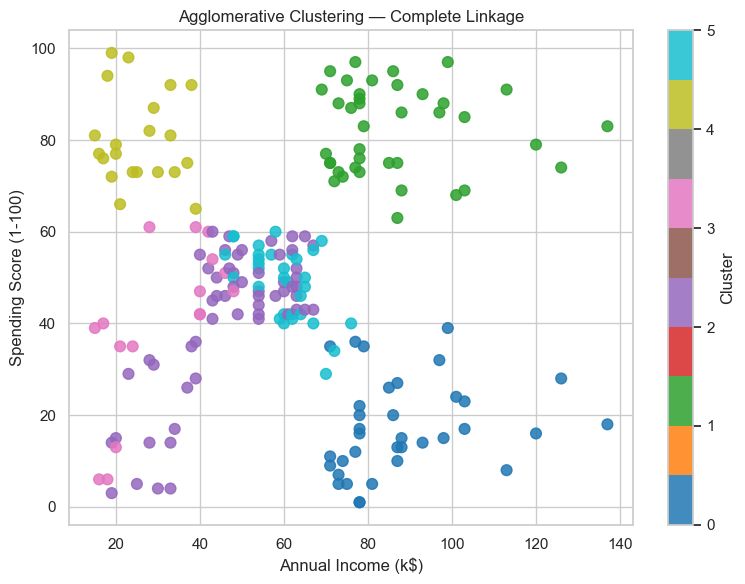

In [13]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"],
                      c=agg_complete_labels, cmap="tab10", s=60, alpha=0.85)
plt.title("Agglomerative Clustering — Complete Linkage")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()


## 9. Model — Agglomerative Hierarchical Clustering (Average linkage)

In [14]:
agg_average_model = AgglomerativeClustering(n_clusters=chosen_k, linkage="average")
agg_average_labels = agg_average_model.fit_predict(X_scaled)
agg_average_metrics = evaluate_clustering("Agglomerative (Average linkage)", agg_average_labels, agg_average_model)



Agglomerative (Average linkage)


,Algorithm,Number of clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Agglomerative (Average linkage),6,0.3896,0.8646,102.037


Cluster sizes:


,Customers
Cluster,
0,20
1,52
2,31
3,39
4,54
5,4


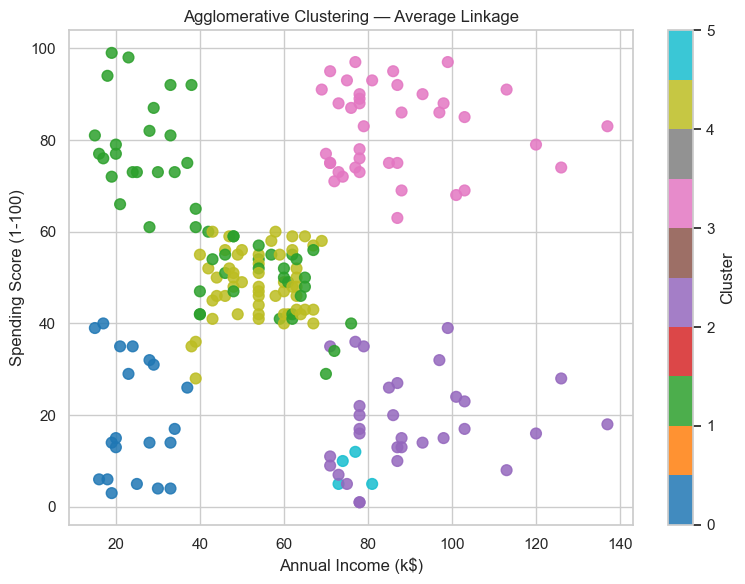

In [15]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"],
                      c=agg_average_labels, cmap="tab10", s=60, alpha=0.85)
plt.title("Agglomerative Clustering — Average Linkage")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()


## 10. Compare all clustering models

,Algorithm,Number of clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,6,0.4284,0.8254,135.1021
1,Agglomerative (Ward linkage),6,0.4201,0.8521,127.9865
2,Agglomerative (Average linkage),6,0.3896,0.8646,102.0370
3,Agglomerative (Complete linkage),6,0.3746,1.0005,109.4154


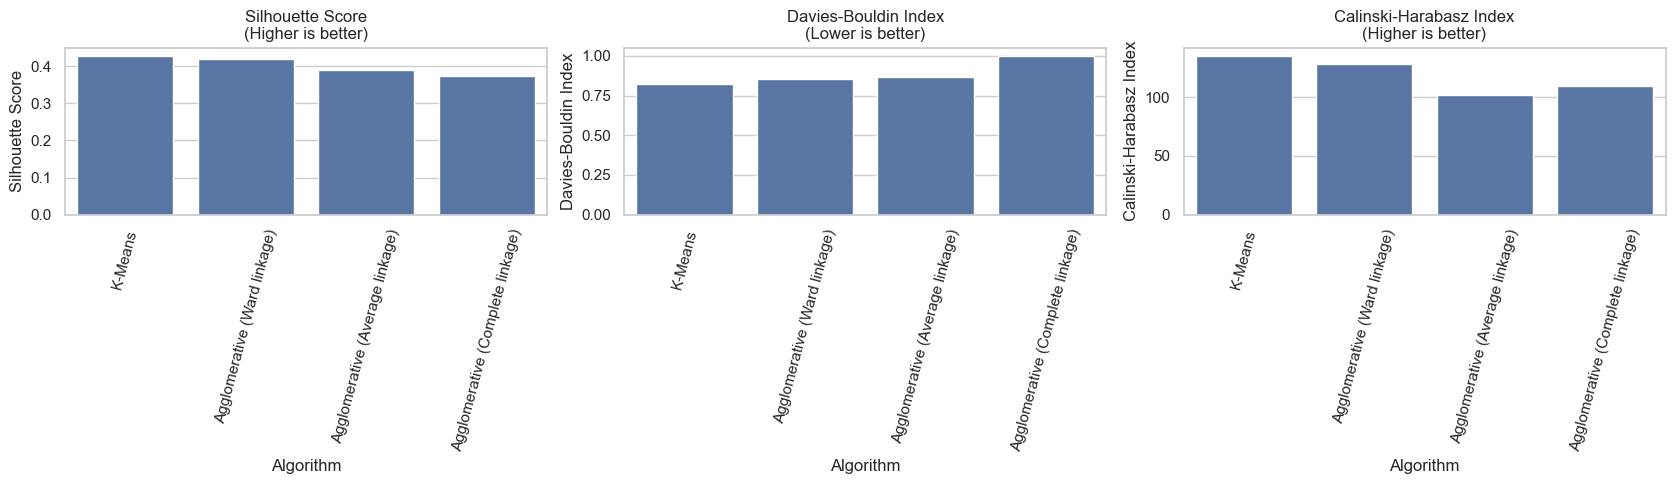

Best silhouette score: K-Means


In [16]:
comparison = pd.DataFrame([item["metrics"] for item in clustering_results.values()])
comparison = comparison.sort_values("Silhouette Score", ascending=False).reset_index(drop=True)
display(comparison.round(4))

# Metric directions: higher Silhouette is better; lower Davies-Bouldin is better;
# higher Calinski-Harabasz is better.
os.makedirs("../datasets", exist_ok=True)
comparison.to_csv("../datasets/clustering_review2_comparison.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
metric_specs = [
    ("Silhouette Score", "Higher is better"),
    ("Davies-Bouldin Index", "Lower is better"),
    ("Calinski-Harabasz Index", "Higher is better"),
]
for ax, (metric, direction) in zip(axes, metric_specs):
    sns.barplot(data=comparison, x="Algorithm", y=metric, ax=ax)
    ax.set_title(f"{metric}\n({direction})")
    ax.tick_params(axis="x", rotation=75)
plt.tight_layout()
plt.show()

print("Best silhouette score:", comparison.iloc[0]["Algorithm"])


## 11. PCA visualisation for every clustering model

PCA explained variance ratio: [0.4427 0.3331]
Total variance shown in 2D: 0.7757


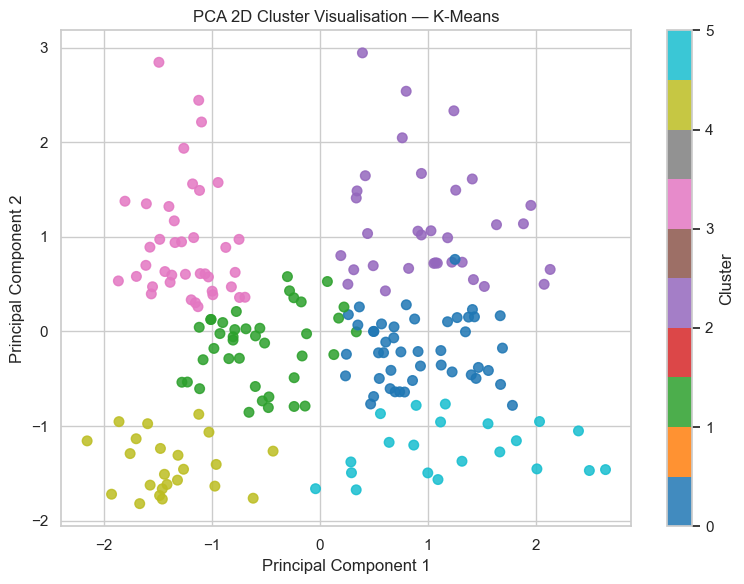

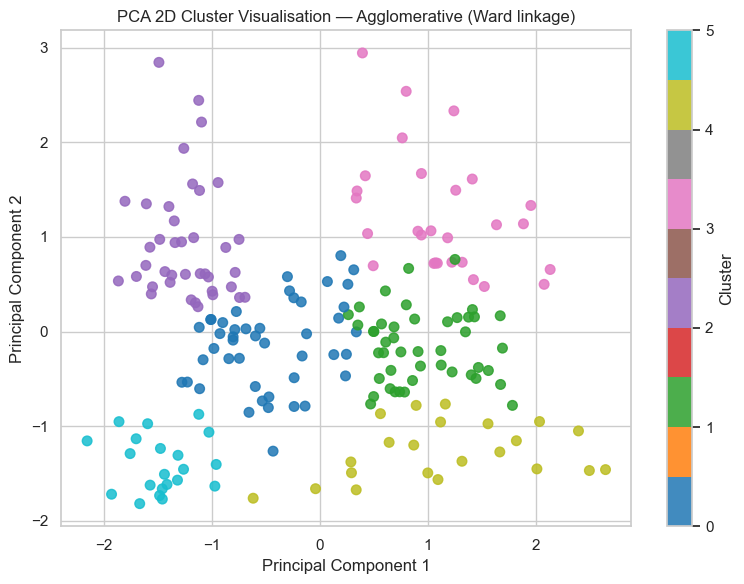

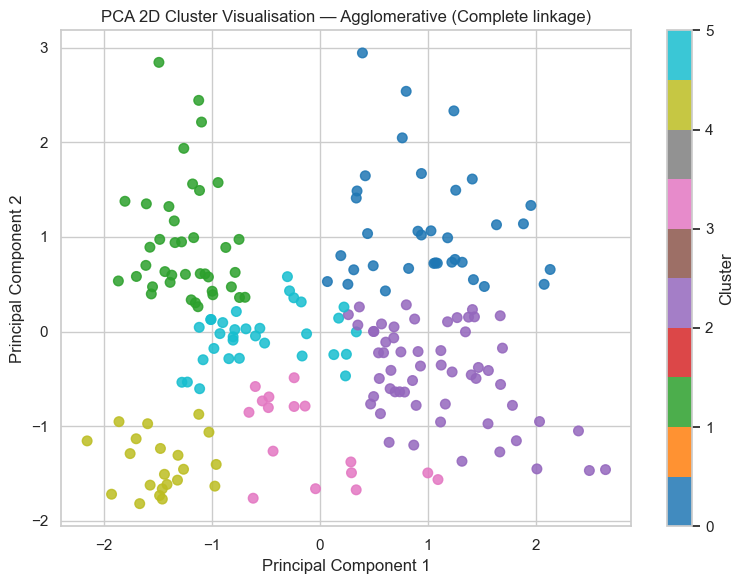

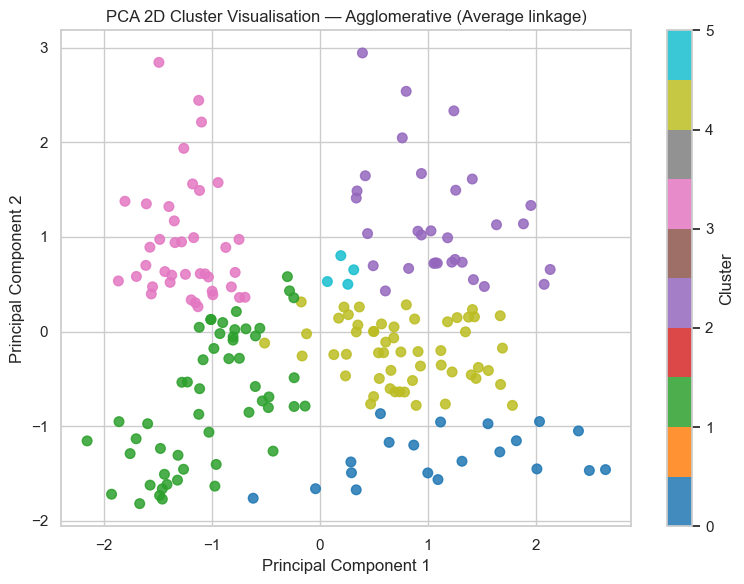

In [17]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("PCA explained variance ratio:", np.round(pca.explained_variance_ratio_, 4))
print("Total variance shown in 2D:", round(pca.explained_variance_ratio_.sum(), 4))

for name, result in clustering_results.items():
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=result["labels"],
                           cmap="tab10", s=48, alpha=0.85)
    plt.title(f"PCA 2D Cluster Visualisation — {name}")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.colorbar(scatter, label="Cluster")
    plt.tight_layout()
    plt.show()


## 12. t-SNE visualisation

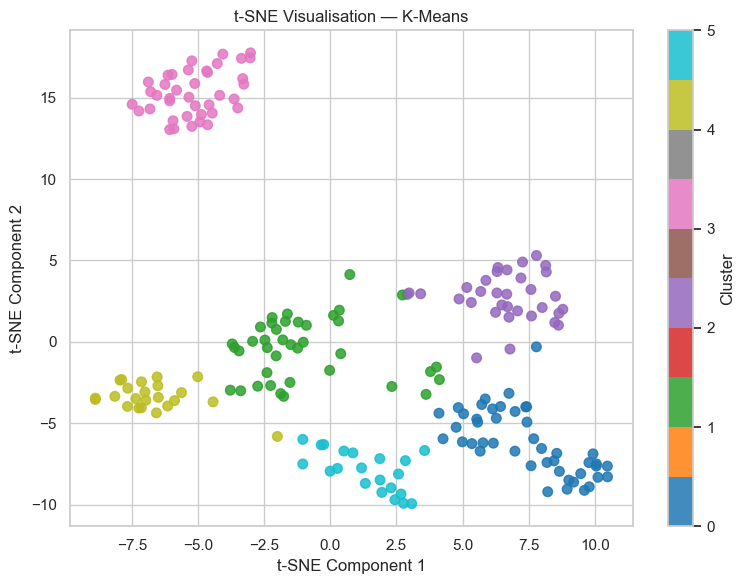

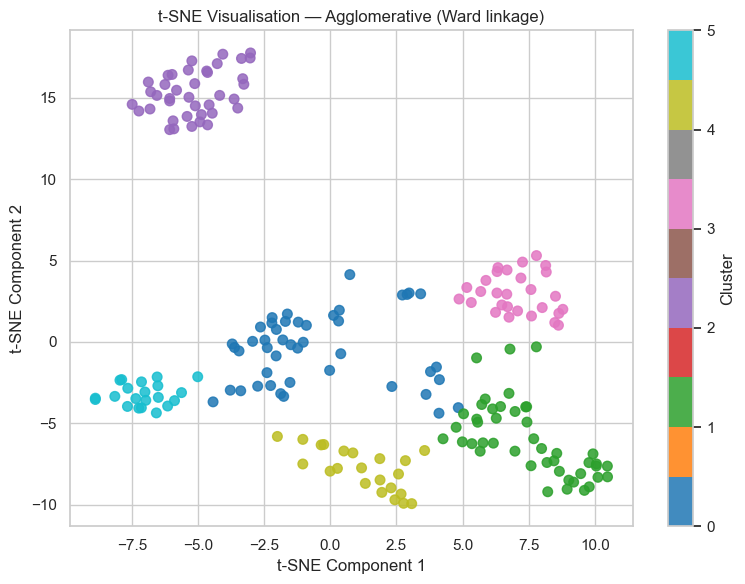

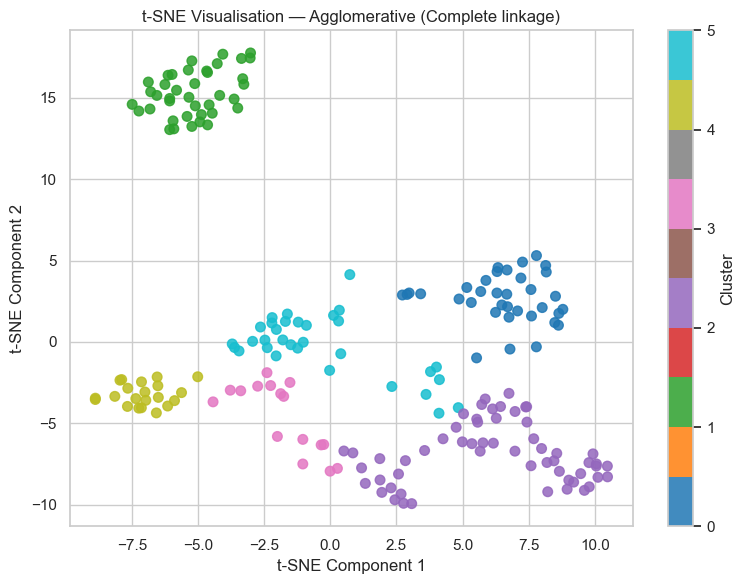

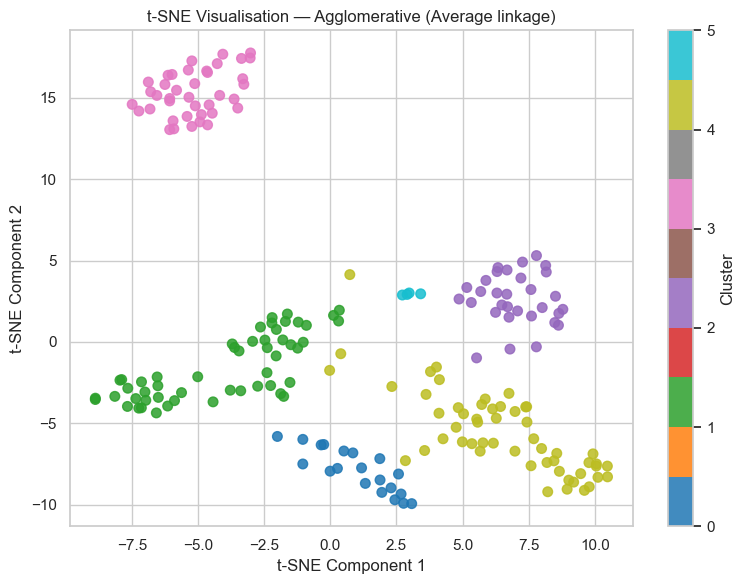

In [18]:
# t-SNE is only a visualisation tool here; it is not used to fit the clusters.
perplexity = min(30, max(5, (len(X_scaled) - 1) // 3))
X_tsne = TSNE(
    n_components=2, perplexity=perplexity, random_state=RANDOM_STATE,
    init="pca", learning_rate="auto"
).fit_transform(X_scaled)

for name, result in clustering_results.items():
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=result["labels"],
                          cmap="tab10", s=48, alpha=0.85)
    plt.title(f"t-SNE Visualisation — {name}")
    plt.xlabel("t-SNE Component 1")
    plt.ylabel("t-SNE Component 2")
    plt.colorbar(scatter, label="Cluster")
    plt.tight_layout()
    plt.show()


## 13. Cluster profiles and interpretation

In [19]:
profile_tables = {}
for name, result in clustering_results.items():
    profile = X.copy()
    profile["Cluster"] = result["labels"]
    means = profile.groupby("Cluster")[features].mean().round(2)
    counts = profile.groupby("Cluster").size().rename("Customer Count")
    means.insert(0, "Customer Count", counts)
    profile_tables[name] = means
    print(f"\n{name} — average customer profile")
    display(means)

# Export individual profiles together in a tidy format.
profile_rows = []
for name, result in clustering_results.items():
    temp = X.copy()
    temp["Cluster"] = result["labels"]
    means = temp.groupby("Cluster")[features].mean().reset_index()
    means.insert(0, "Algorithm", name)
    counts = temp.groupby("Cluster").size().rename("Customer Count").reset_index()
    means = means.merge(counts, on="Cluster", how="left")
    profile_rows.append(means)

all_profiles = pd.concat(profile_rows, ignore_index=True)
all_profiles.to_csv("../datasets/clustering_cluster_profiles.csv", index=False)
print("Saved cluster profiles to ../datasets/clustering_cluster_profiles.csv")



K-Means — average customer profile


,Customer Count,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
0,45,56.33,54.27,49.07
1,39,26.79,57.10,48.13
2,33,41.94,88.94,16.97
3,39,32.69,86.54,82.13
4,23,25.00,25.26,77.61
5,21,45.52,26.29,19.38



Agglomerative (Ward linkage) — average customer profile


,Customer Count,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
0,45,27.38,57.51,45.84
1,45,56.40,55.29,48.36
2,39,32.69,86.54,82.13
3,28,43.89,91.29,16.68
4,22,44.32,25.77,20.27
5,21,24.81,25.62,80.24



Agglomerative (Complete linkage) — average customer profile


,Customer Count,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
0,35,41.69,88.23,17.29
1,39,32.69,86.54,82.13
2,57,55.33,47.32,41.09
3,16,30.50,31.06,39.94
4,21,24.81,25.62,80.24
5,32,27.28,59.91,48.94



Agglomerative (Average linkage) — average customer profile


,Customer Count,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
0,20,43.90,24.45,19.10
1,52,24.65,42.94,62.08
2,31,44.39,89.77,18.48
3,39,32.69,86.54,82.13
4,54,53.26,54.20,48.56
5,4,20.75,76.25,8.00


Saved cluster profiles to ../datasets/clustering_cluster_profiles.csv


## 14. How to explain the results

- **Silhouette Score:** ranges approximately from -1 to 1; higher values indicate better separation and cohesion.
- **Davies–Bouldin Index:** lower values indicate clusters that are more distinct relative to their within-cluster spread.
- **Calinski–Harabasz Index:** higher values generally indicate better separation relative to within-cluster dispersion.
- **Cluster sizes and profiles:** explain how many customers belong to each group and what their average age, income, and spending score look like.
- **PCA/t-SNE:** provide 2D visual summaries only. The clustering algorithms are fitted on the original three standardised features.
- **No confusion matrix:** there are no known true cluster labels to compare against. Internal validation metrics are the appropriate evaluation here.

Do not assume that a cluster number has an intrinsic meaning. Interpret it from the profile values, for example, a segment with high income and high spending score.
